## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs('images', exist_ok=True)
pd.set_option('display.float_format', '{:.2f}'.format)

DATA_PATH = os.path.dirname(glob.glob('/kaggle/input/**/sales.csv', recursive=True)[0]) + '/'
print('Data path:', DATA_PATH)

def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.tick_params(axis='x', rotation=45)

Data path: /kaggle/input/datasets/svizor/retail-sales-forecasting-data/


In [2]:
sales = pd.read_csv(DATA_PATH + 'sales.csv').drop(columns=['Unnamed: 0'], errors='ignore')
sales['date'] = pd.to_datetime(sales['date'])

# 1) Remove returns and data errors
sales = sales[(sales['quantity'] > 0) & (sales['price_base'] > 0)]

# 2) Remove packaging items (paid bags), found in Part 1
catalog = pd.read_csv(DATA_PATH + 'catalog.csv').drop(columns=['Unnamed: 0'], errors='ignore')
aux_dept  = catalog.loc[catalog['item_id'] == 'b0d24502fb66', 'dept_name'].iloc[0]
aux_items = catalog[catalog['dept_name'] == aux_dept]['item_id']
exclude   = set(aux_items) | {'327c5bc1e583'}
sales = sales[~sales['item_id'].isin(exclude)].copy()

print('Rows:', len(sales))
print('Items:', sales['item_id'].nunique())
print('Item-store pairs:', sales.groupby(['item_id', 'store_id']).ngroups)

Rows: 7408566
Items: 28083
Item-store pairs: 57787


## 2. Assortment & ABC Analysis

In [3]:
matrix = pd.read_csv(DATA_PATH + 'actual_matrix.csv').drop(columns=['Unnamed: 0'], errors='ignore')

print(matrix.shape)
print()
print(matrix.nunique())
matrix.head()

(35202, 3)

item_id     15398
date         1325
store_id        4
dtype: int64


,item_id,date,store_id
0,c578da8e8841,2019-10-17,1
1,4dd2b686802c,2019-10-17,1
2,16ade2e3fca9,2019-10-17,1
3,f4eb16dab09e,2019-10-17,1
4,ab1384c2af6d,2020-05-31,1


In [4]:
last_date = sales['date'].max()
recent = sales[sales['date'] > last_date - pd.Timedelta(days=365)]

# Keep only items currently in each store's assortment
active = matrix[['item_id', 'store_id']].drop_duplicates()
recent = recent.merge(active, on=['item_id', 'store_id'], how='inner')

# Revenue, quantity and selling days per item-store
abc = (recent.groupby(['store_id', 'item_id'])
             .agg(revenue=('sum_total', 'sum'),
                  quantity=('quantity', 'sum'),
                  days_sold=('date', 'nunique'))
             .reset_index())

# Cumulative revenue share inside each store
abc = abc.sort_values(['store_id', 'revenue'], ascending=[True, False])
abc['cum_share'] = (abc.groupby('store_id')['revenue'].cumsum() /
                    abc.groupby('store_id')['revenue'].transform('sum'))

abc['abc_class'] = np.where(abc['cum_share'] <= 0.80, 'A',
                   np.where(abc['cum_share'] <= 0.95, 'B', 'C'))

print('Active item-store pairs with sales:', len(abc))
abc.head(10)

Active item-store pairs with sales: 31811


,store_id,item_id,revenue,quantity,days_sold,cum_share,abc_class
7625,1,9a7e315f3f42,73193488.25,120979.82,365,0.06,A
5475,1,6e773babf31f,14871749.87,9698.90,361,0.07,A
5765,1,7428830d55b6,13086961.52,37548.85,364,0.08,A
432,1,0973df3ff57f,12601172.48,99435.69,365,0.09,A
6854,1,89caab19e9d0,8988082.35,28778.46,360,0.10,A
4076,1,52738439ad17,8292951.58,17874.92,357,0.10,A
7659,1,9b4865c6faf1,6492946.73,57809.00,358,0.11,A
11861,1,f202f07102b7,6316283.18,3832.00,351,0.11,A
11371,1,e913f9e57c69,5514729.39,34220.82,363,0.12,A
6071,1,79fdc441b59f,5345695.16,40646.00,365,0.12,A


In [5]:
summary_abc = abc.groupby(['store_id', 'abc_class']).agg(
    items=('item_id', 'count'),
    revenue=('revenue', 'sum'),
    avg_days_sold=('days_sold', 'mean'))

summary_abc['items_%']   = summary_abc['items'] / summary_abc.groupby('store_id')['items'].transform('sum') * 100
summary_abc['revenue_%'] = summary_abc['revenue'] / summary_abc.groupby('store_id')['revenue'].transform('sum') * 100

summary_abc[['items', 'items_%', 'revenue_%', 'avg_days_sold']].round(1)

items  items_%  revenue_%  avg_days_sold
store_id abc_class                                          
1        A           2296    18.40      80.00         261.40
         B           3901    31.20      15.00         162.40
         C           6298    50.40       5.00          51.40
2        A           1322    28.30      80.00         221.50
         B           1477    31.60      15.00         121.50
         C           1880    40.20       5.00          40.30
3        A            592    27.80      80.00         253.20
         B            688    32.30      15.00         174.20
         C            853    40.00       5.00          70.20
4        A           2224    17.80      80.00         217.80
         B           3821    30.60      15.00         142.30
         C           6459    51.70       5.00          50.60

## 3. Daily Data with Zero-Sales Days

count   6434.00
mean       0.70
std        0.25
min        0.01
25%        0.52
50%        0.77
75%        0.93
max        1.00
Name: sell_rate, dtype: float64


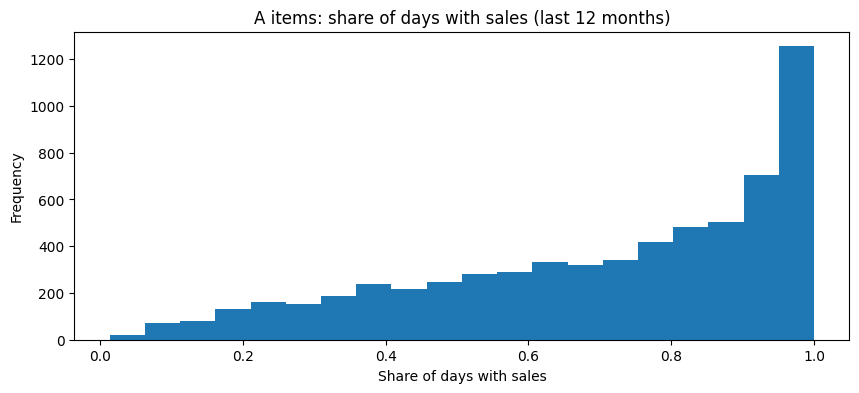

In [6]:
store_days = recent.groupby('store_id')['date'].nunique()
abc['sell_rate'] = abc['days_sold'] / abc['store_id'].map(store_days)

a_items = abc[abc['abc_class'] == 'A']
print(a_items['sell_rate'].describe().round(2))

a_items['sell_rate'].plot(kind='hist', bins=20, figsize=(10, 4),
                          title='A items: share of days with sales (last 12 months)')
plt.xlabel('Share of days with sales')
plt.show()

In [7]:
# A items only
a_pairs = a_items[['store_id', 'item_id']]
a_sales = (sales.merge(a_pairs, on=['store_id', 'item_id'], how='inner')
                .groupby(['store_id', 'item_id', 'date'])['quantity'].sum()
                .reset_index())

# Wide table: one row per day, one column per item-store
wide = a_sales.pivot_table(index='date', columns=['store_id', 'item_id'],
                           values='quantity', aggfunc='sum')
wide = wide.reindex(pd.date_range(wide.index.min(), last_date, freq='D'))

# Zeros only after the first sale of each item-store
alive = wide.notna().cummax()
wide  = wide.fillna(0).where(alive)

# Back to long format
daily = (wide.stack(['store_id', 'item_id'], future_stack=True)
             .dropna()
             .reset_index())
daily.columns = ['date', 'store_id', 'item_id', 'quantity']

print('Rows:', len(daily))
print('Series:', daily.groupby(['store_id', 'item_id']).ngroups)
print(f"Share of zero days: {(daily['quantity'] == 0).mean():.1%}")
daily.head()

Rows: 3481523
Series: 6434
Share of zero days: 29.6%


,date,store_id,item_id,quantity
0,2022-08-28,1,001829cb707d,7.00
1,2022-08-28,1,002f51c34a7a,4.00
2,2022-08-28,1,0063a7918c2c,3.00
3,2022-08-28,1,00727e9b17f7,0.76
4,2022-08-28,1,0082d7c4d384,13.60


## 4. Train / Test Split & Baselines

In [8]:
TEST_DAYS = 30
split_date = last_date - pd.Timedelta(days=TEST_DAYS)
wide.index.name = 'date'

train_wide = wide.loc[:split_date]
test_wide  = wide.loc[split_date + pd.Timedelta(days=1):]

print('Train:', train_wide.index.min().date(), '->', train_wide.index.max().date())
print('Test: ', test_wide.index.min().date(), '->', test_wide.index.max().date())

def weekday_forecast(train, test_index, weeks):
    recent = train.tail(7 * weeks)
    profile = recent.groupby(recent.index.dayofweek).mean()
    forecast = profile.loc[test_index.dayofweek]
    forecast.index = test_index
    return forecast

baselines = {
    'Seasonal naive (last week)': weekday_forecast(train_wide, test_wide.index, weeks=1),
    'Weekday avg (last 4 weeks)': weekday_forecast(train_wide, test_wide.index, weeks=4),
}

Train: 2022-08-28 -> 2024-08-27
Test:  2024-08-28 -> 2024-09-26


In [9]:
def wape(actual, forecast):
    return (actual - forecast.fillna(0)).abs().sum().sum() / actual.sum().sum()

results = {}
for name, fc in baselines.items():
    row = {store: wape(test_wide[store], fc[store]) for store in [1, 2, 3, 4]}
    row['All'] = wape(test_wide, fc)
    results[name] = row

results = pd.DataFrame(results) * 100
results.round(1)

,Seasonal naive (last week),Weekday avg (last 4 weeks)
1,51.80,45.90
2,67.90,59.30
3,50.20,44.50
4,51.30,45.50
All,52.90,46.80


## 5. LightGBM (Global Model)

In [10]:
w = wide
past = w.shift(30)   # only information at least 30 days old -> no leakage

feature_tables = {
    'lag_35':  w.shift(35),
    'lag_42':  w.shift(42),
    'lag_364': w.shift(364),
    'same_weekday_mean_4w': (w.shift(35) + w.shift(42) + w.shift(49) + w.shift(56)) / 4,
    'mean_7_lag30':  past.rolling(7,  min_periods=1).mean(),
    'mean_28_lag30': past.rolling(28, min_periods=1).mean(),
    'mean_91_lag30': past.rolling(91, min_periods=1).mean(),
    'sold_share_28_lag30': (past > 0).astype(float).where(past.notna())
                                      .rolling(28, min_periods=1).mean(),
}

# Wide -> long, one column per feature
df = w.stack(['store_id', 'item_id'], future_stack=True).rename('quantity').to_frame()
for name, table in feature_tables.items():
    df[name] = table.stack(['store_id', 'item_id'], future_stack=True)
df = df.dropna(subset=['quantity']).reset_index()

# Calendar features
df['dayofweek'] = df['date'].dt.dayofweek
df['month']     = df['date'].dt.month

peak_days = pd.to_datetime([
    '2022-12-29', '2022-12-30', '2022-12-31',
    '2023-12-29', '2023-12-30', '2023-12-31',
    '2023-03-07', '2023-03-08', '2024-03-07', '2024-03-08',
    '2023-04-15', '2024-05-04',
])
df['is_peak_day'] = df['date'].isin(peak_days).astype(int)
df['is_jan_1_2']  = ((df['date'].dt.month == 1) & (df['date'].dt.day <= 2)).astype(int)

# Category features: store and department
dept = catalog.drop_duplicates('item_id').set_index('item_id')['dept_name']
df['dept']  = df['item_id'].map(dept).astype('category')
df['store'] = df['store_id'].astype('category')

print(df.shape)
df.tail()

(3481523, 18)


,date,store_id,item_id,quantity,lag_35,lag_42,lag_364,same_weekday_mean_4w,mean_7_lag30,mean_28_lag30,mean_91_lag30,sold_share_28_lag30,dayofweek,month,is_peak_day,is_jan_1_2,dept,store
3481518,2024-09-26,4,ff733b650f7f,11.00,0.00,0.00,NaN,0.00,1.29,0.96,1.62,0.46,3,9,0,0,НАБОРЫ КОНФЕТ,4
3481519,2024-09-26,4,ff7f8949b1b2,0.00,0.00,1.00,NaN,0.50,0.43,0.50,0.54,0.50,3,9,0,0,КОНЬЯК,4
3481520,2024-09-26,4,ff98ba8bebb4,29.12,38.37,44.11,NaN,44.78,44.90,48.50,51.25,1.00,3,9,0,0,ОВОЩИ,4
3481521,2024-09-26,4,ffc2aa4c7c14,3.00,11.00,12.00,NaN,9.75,10.29,10.64,10.95,1.00,3,9,0,0,ПИВО,4
3481522,2024-09-26,4,fff9aabc5046,0.00,1.00,0.00,NaN,0.25,0.14,0.07,0.07,0.07,3,9,0,0,КРЕПКИЕ АЛКОГОЛЬНЫЕ НАПИТКИ,4


In [11]:
import lightgbm as lgb

features = ['store', 'dept', 'dayofweek', 'month', 'is_peak_day', 'is_jan_1_2',
            'lag_35', 'lag_42', 'lag_364', 'same_weekday_mean_4w',
            'mean_7_lag30', 'mean_28_lag30', 'mean_91_lag30', 'sold_share_28_lag30']

train_df = df[(df['date'] <= split_date) & df['mean_28_lag30'].notna()]
train_df = train_df[~((train_df['store_id'] == 4) & (train_df['date'] < '2024-02-01'))]
test_df  = df[df['date'] > split_date].copy()
print('Train rows:', len(train_df), '| Test rows:', len(test_df))

model = lgb.LGBMRegressor(objective='tweedie',
                          n_estimators=500, learning_rate=0.05,
                          num_leaves=63, min_child_samples=100,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=42, verbose=-1)
model.fit(train_df[features], train_df['quantity'])

test_df['forecast'] = model.predict(test_df[features])

Train rows: 3059474 | Test rows: 193012


In [12]:
lgb_wide = test_df.pivot_table(index='date', columns=['store_id', 'item_id'], values='forecast')
lgb_wide = lgb_wide.reindex(columns=test_wide.columns)
baselines['LightGBM'] = lgb_wide

results = {}
for name, fc in baselines.items():
    row = {store: wape(test_wide[store], fc[store]) for store in [1, 2, 3, 4]}
    row['All'] = wape(test_wide, fc)
    results[name] = row

results = (pd.DataFrame(results) * 100).round(1)
results

,Seasonal naive (last week),Weekday avg (last 4 weeks),LightGBM
1,51.80,45.90,44.30
2,67.90,59.30,57.30
3,50.20,44.50,46.00
4,51.30,45.50,44.80
All,52.90,46.80,45.80


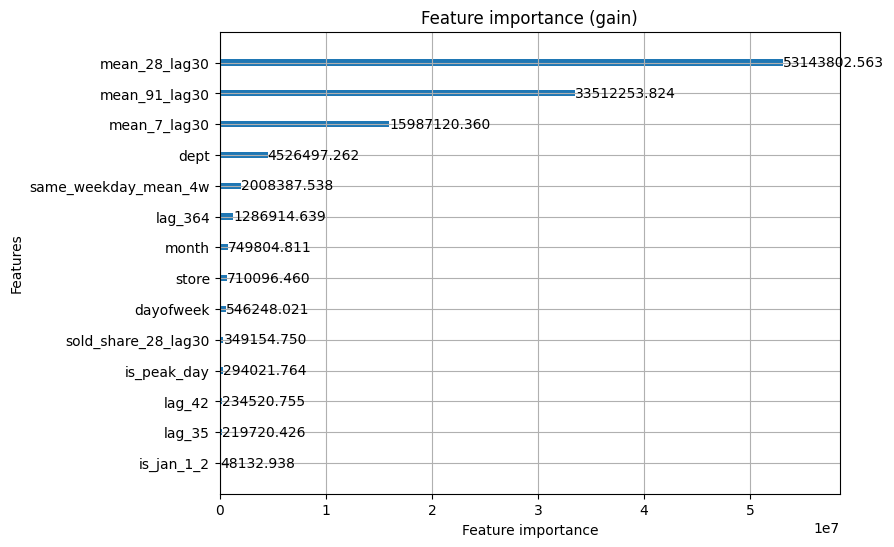

In [13]:
lgb.plot_importance(model, importance_type='gain', figsize=(8, 6),
                    title='Feature importance (gain)')
plt.show()

## 6. Model Comparison by Planning Level

In [14]:
# Ensemble: average of LightGBM and the best baseline
baselines['Ensemble'] = (baselines['LightGBM'].fillna(0) +
                         baselines['Weekday avg (last 4 weeks)'].fillna(0)) / 2

def evaluate(actual, forecasts):
    out = {}
    for name, fc in forecasts.items():
        row = {store: wape(actual[store], fc[store]) for store in [1, 2, 3, 4]}
        row['All'] = wape(actual, fc)
        out[name] = row
    return (pd.DataFrame(out) * 100).round(1)

# Weekly level: first 28 test days = 4 full weeks
week = np.arange(len(test_wide)) // 7
mask = week < 4

def to_weekly(table):
    return table[mask].fillna(0).groupby(week[mask]).sum()

print('Daily WAPE %')
display(evaluate(test_wide, baselines))

print('Weekly WAPE %')
display(evaluate(to_weekly(test_wide),
                 {name: to_weekly(fc) for name, fc in baselines.items()}))

Daily WAPE %


,Seasonal naive (last week),Weekday avg (last 4 weeks),LightGBM,Ensemble
1,51.80,45.90,44.30,43.20
2,67.90,59.30,57.30,56.80
3,50.20,44.50,46.00,44.00
4,51.30,45.50,44.80,43.70
All,52.90,46.80,45.80,44.70


Weekly WAPE %


,Seasonal naive (last week),Weekday avg (last 4 weeks),LightGBM,Ensemble
1,31.50,29.90,30.30,28.60
2,37.70,35.40,35.30,34.30
3,26.50,27.10,30.80,28.10
4,30.70,29.40,30.70,29.10
All,31.20,29.90,31.00,29.30


In [15]:
def to_monthly(table):
    return table.fillna(0).sum().to_frame().T

print('Monthly WAPE % (30-day total per item-store)')
display(evaluate(to_monthly(test_wide),
                 {name: to_monthly(fc) for name, fc in baselines.items()}))

Monthly WAPE % (30-day total per item-store)


,Seasonal naive (last week),Weekday avg (last 4 weeks),LightGBM,Ensemble
1,27.10,24.10,23.10,21.60
2,31.50,27.70,26.20,25.70
3,22.40,22.40,25.10,22.80
4,25.70,23.30,24.10,22.60
All,26.40,23.90,24.00,22.50


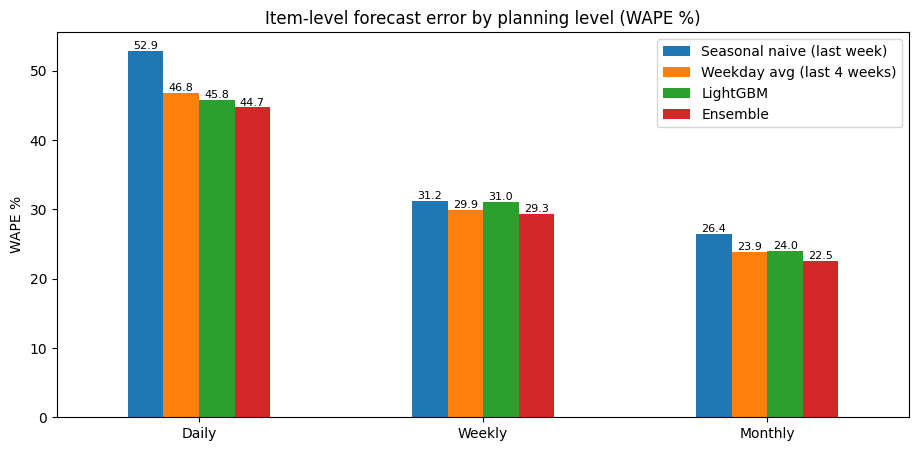

In [16]:
levels = pd.DataFrame({
    'Daily':   evaluate(test_wide, baselines).loc['All'],
    'Weekly':  evaluate(to_weekly(test_wide), {n: to_weekly(f) for n, f in baselines.items()}).loc['All'],
    'Monthly': evaluate(to_monthly(test_wide), {n: to_monthly(f) for n, f in baselines.items()}).loc['All'],
})
levels.to_csv('item_level_wape_by_planning_level.csv')

ax = levels.T.plot(kind='bar', figsize=(11, 5), rot=0,
                   title='Item-level forecast error by planning level (WAPE %)')
ax.set_ylabel('WAPE %')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8)
plt.savefig('images/error_by_planning_level.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Final Forecast & Weekly Demand Plan

In [17]:
# Same feature code as in section 5, wrapped in a function so we can reuse it
def build_features(w):
    past = w.shift(30)
    tables = {
        'lag_35':  w.shift(35),
        'lag_42':  w.shift(42),
        'lag_364': w.shift(364),
        'same_weekday_mean_4w': (w.shift(35) + w.shift(42) + w.shift(49) + w.shift(56)) / 4,
        'mean_7_lag30':  past.rolling(7,  min_periods=1).mean(),
        'mean_28_lag30': past.rolling(28, min_periods=1).mean(),
        'mean_91_lag30': past.rolling(91, min_periods=1).mean(),
        'sold_share_28_lag30': (past > 0).astype(float).where(past.notna())
                                          .rolling(28, min_periods=1).mean(),
    }
    out = w.stack(['store_id', 'item_id'], future_stack=True).rename('quantity').to_frame()
    for name, t in tables.items():
        out[name] = t.stack(['store_id', 'item_id'], future_stack=True)
    out = out.reset_index()
    out['dayofweek']   = out['date'].dt.dayofweek
    out['month']       = out['date'].dt.month
    out['is_peak_day'] = out['date'].isin(peak_days).astype(int)
    out['is_jan_1_2']  = ((out['date'].dt.month == 1) & (out['date'].dt.day <= 2)).astype(int)
    out['dept']  = out['item_id'].map(dept).astype('category')
    out['store'] = out['store_id'].astype('category')
    return out

# 1) Add 30 empty future days to the wide table and build features
future_index = pd.date_range(last_date + pd.Timedelta(days=1), periods=30, freq='D')
wide_ext = wide.reindex(pd.date_range(wide.index.min(), future_index.max(), freq='D'))
wide_ext.index.name = 'date'
full = build_features(wide_ext)

# 2) Retrain LightGBM on ALL known data
train_all = full[(full['date'] <= last_date) & full['quantity'].notna() & full['mean_28_lag30'].notna()]
train_all = train_all[~((train_all['store_id'] == 4) & (train_all['date'] < '2024-02-01'))]

final_model = lgb.LGBMRegressor(**model.get_params())
final_model.fit(train_all[features], train_all['quantity'])

future_df = full[full['date'] > last_date].copy()
future_df['lgbm'] = final_model.predict(future_df[features])
lgbm_future = (future_df.pivot_table(index='date', columns=['store_id', 'item_id'], values='lgbm')
                        .reindex(columns=wide.columns))

# 3) Weekday average on ALL known data
wa_future = weekday_forecast(wide, future_index, weeks=4)

# 4) Ensemble
final = (lgbm_future.fillna(0) + wa_future.fillna(0)) / 2
final.index.name = 'date'

print('Forecast:', final.index.min().date(), '->', final.index.max().date())
print('Series:', final.shape[1])

Forecast: 2024-09-27 -> 2024-10-26
Series: 6434


In [18]:
# Weekly buckets: 7-day blocks starting from the first forecast day
week_no = np.arange(len(final)) // 7
labels = []
for i in sorted(set(week_no)):
    days = future_index[week_no == i]
    labels.append(f"{days.min():%d %b} - {days.max():%d %b}")

plan = final.groupby(week_no).sum().T
plan.columns = labels
plan['Total (30 days)'] = final.sum()
plan = plan.round(1).reset_index()
plan['dept'] = plan['item_id'].map(dept)
plan = plan.sort_values(['store_id', 'Total (30 days)'], ascending=[True, False])

# Save outputs
plan.to_csv('weekly_demand_plan.csv', index=False)
(final.stack(['store_id', 'item_id'], future_stack=True)
      .rename('forecast').round(2).reset_index()
      .to_csv('item_forecast_next_30_days.csv', index=False))

plan.head(10)

,store_id,item_id,27 Sep - 03 Oct,04 Oct - 10 Oct,11 Oct - 17 Oct,18 Oct - 24 Oct,25 Oct - 26 Oct,Total (30 days),dept
812,1,5b8e114fdf6f,2761.30,2688.10,2762.10,2699.90,1001.10,11912.50,ФРУКТЫ
1394,1,9a7e315f3f42,2372.80,2380.80,2382.80,2352.60,838.70,10327.70,ДОМАШНЯЯ КУХНЯ
2049,1,e5b2b6f57ea7,2233.60,2304.10,2355.70,2358.60,613.10,9865.00,КАФЕ
419,1,2e58990eaa3c,1997.90,1866.20,1835.00,1540.70,451.30,7690.90,ОВОЩИ
82,1,0973df3ff57f,1342.10,1361.60,1377.20,1426.60,512.30,6019.80,ФРУКТЫ
1537,1,ad5239463b05,1315.70,1335.50,1303.30,1294.20,400.90,5649.50,ПИРОГИ
986,1,6d284b4e9982,1264.10,1257.10,1250.10,1246.10,387.60,5404.90,САХАР
905,1,645f94a90143,1165.90,1167.00,1183.30,1169.20,395.60,5080.90,ХЛЕБ
1397,1,9b4865c6faf1,1044.30,1135.90,1075.20,1128.20,362.00,4745.50,ЯЙЦО
398,1,2c007023f650,912.00,904.90,915.30,948.80,247.20,3928.30,КАФЕ


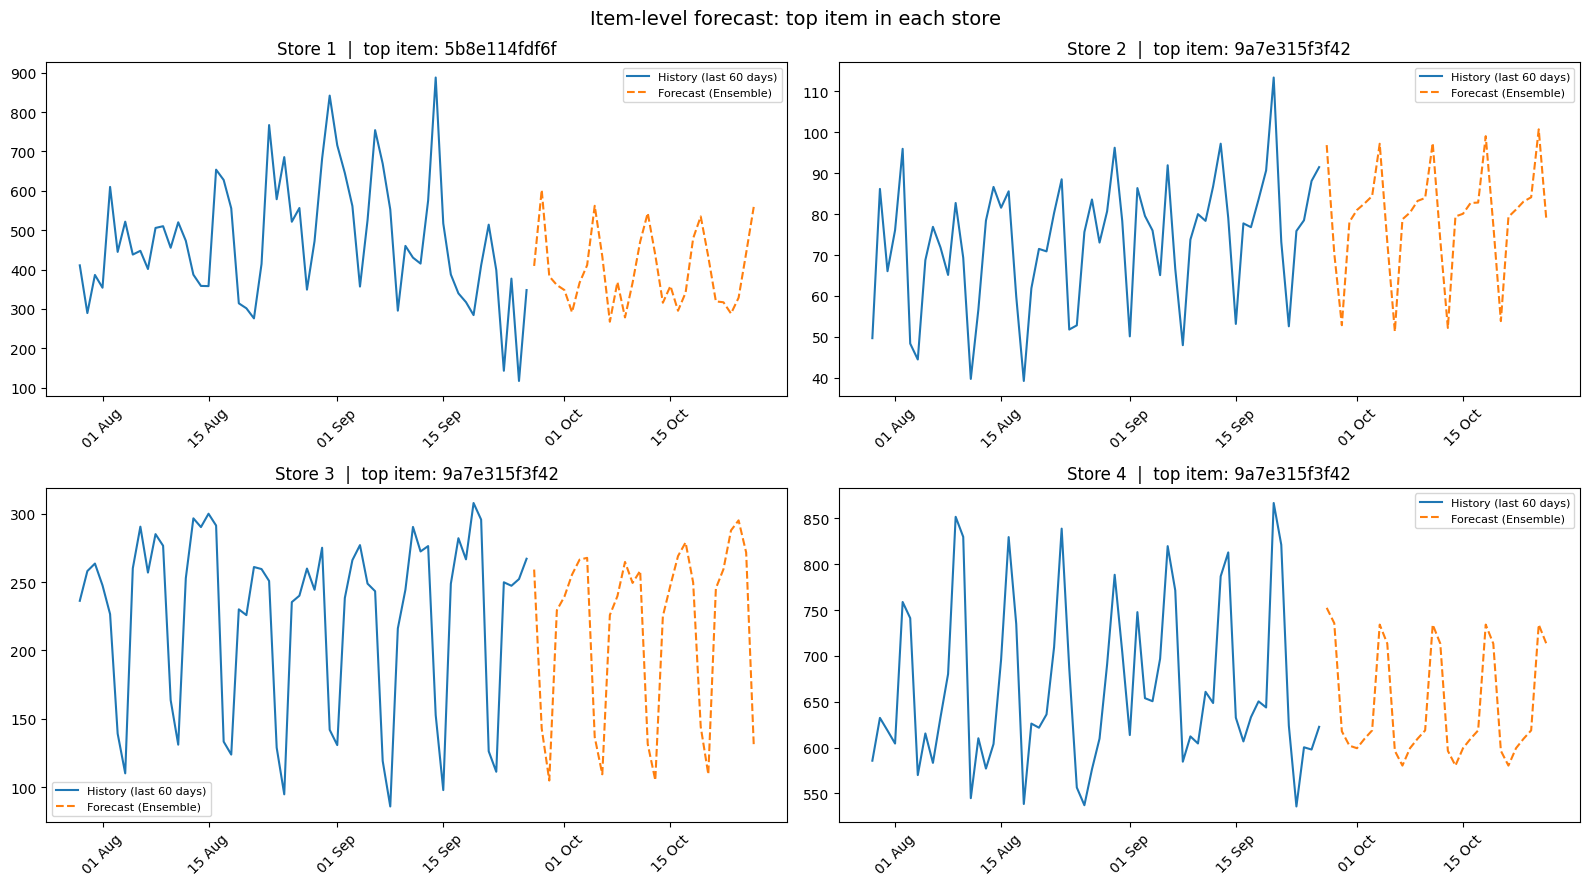

In [19]:
top = plan.groupby('store_id').head(1)   # plan is already sorted by total

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (_, row) in zip(axes.flat, top.iterrows()):
    key = (row['store_id'], row['item_id'])
    ax.plot(wide[key].tail(60), label='History (last 60 days)')
    ax.plot(final[key], linestyle='--', label='Forecast (Ensemble)')
    ax.set_title(f"Store {row['store_id']}  |  top item: {row['item_id']}")
    ax.legend(fontsize=8)
    format_dates(ax)

plt.suptitle('Item-level forecast: top item in each store', fontsize=14)
plt.tight_layout()
plt.savefig('images/item_forecast_top_items.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
for store in [1, 2, 3, 4]:
    store_plan = plan[plan['store_id'] == store]
    print(f'Store {store}: {len(store_plan)} A items')
    display(store_plan.head(5))

Store 1: 2296 A items


,store_id,item_id,27 Sep - 03 Oct,04 Oct - 10 Oct,11 Oct - 17 Oct,18 Oct - 24 Oct,25 Oct - 26 Oct,Total (30 days),dept
812,1,5b8e114fdf6f,2761.30,2688.10,2762.10,2699.90,1001.10,11912.50,ФРУКТЫ
1394,1,9a7e315f3f42,2372.80,2380.80,2382.80,2352.60,838.70,10327.70,ДОМАШНЯЯ КУХНЯ
2049,1,e5b2b6f57ea7,2233.60,2304.10,2355.70,2358.60,613.10,9865.00,КАФЕ
419,1,2e58990eaa3c,1997.90,1866.20,1835.00,1540.70,451.30,7690.90,ОВОЩИ
82,1,0973df3ff57f,1342.10,1361.60,1377.20,1426.60,512.30,6019.80,ФРУКТЫ


Store 2: 1322 A items


,store_id,item_id,27 Sep - 03 Oct,04 Oct - 10 Oct,11 Oct - 17 Oct,18 Oct - 24 Oct,25 Oct - 26 Oct,Total (30 days),dept
3103,2,9a7e315f3f42,546.20,547.90,548.30,557.80,179.50,2379.70,ДОМАШНЯЯ КУХНЯ
3477,2,e5b2b6f57ea7,494.50,500.80,499.80,515.60,131.80,2142.50,КАФЕ
3554,2,f1eb9c33424e,373.60,380.20,387.90,402.40,124.20,1668.20,ПИЦЦА
3014,2,89caab19e9d0,341.90,342.30,347.00,361.50,121.20,1513.80,СВЕЖЕЕ МЯСО
2766,2,5b8e114fdf6f,280.60,337.50,321.60,319.10,83.70,1342.50,ФРУКТЫ


Store 3: 592 A items


,store_id,item_id,27 Sep - 03 Oct,04 Oct - 10 Oct,11 Oct - 17 Oct,18 Oct - 24 Oct,25 Oct - 26 Oct,Total (30 days),dept
3974,3,9a7e315f3f42,1497.30,1493.30,1515.40,1590.60,402.40,6499.10,ДОМАШНЯЯ КУХНЯ
4132,3,e5b2b6f57ea7,1259.20,1243.50,1256.40,1236.60,291.50,5287.20,КАФЕ
3756,3,3d33703a2b2f,793.70,714.80,724.40,718.00,190.20,3141.10,ВОДА
3888,3,78f56d81c9b1,639.10,633.90,629.60,635.80,175.20,2713.50,ЭНЕРГЕТИКИ
4178,3,f1eb9c33424e,630.10,626.20,619.50,629.90,167.90,2673.60,ПИЦЦА


Store 4: 2224 A items


,store_id,item_id,27 Sep - 03 Oct,04 Oct - 10 Oct,11 Oct - 17 Oct,18 Oct - 24 Oct,25 Oct - 26 Oct,Total (30 days),dept
5560,4,9a7e315f3f42,4536.10,4452.50,4452.50,4452.50,1447.70,19341.30,ДОМАШНЯЯ КУХНЯ
5017,4,5b8e114fdf6f,3495.10,3370.20,3370.20,3299.70,1191.00,14726.00,ФРУКТЫ
4786,4,406d445f0987,889.60,899.10,898.10,839.60,284.80,3811.20,ФРУКТЫ
4629,4,2e58990eaa3c,884.70,747.40,701.40,721.80,226.00,3281.20,ОВОЩИ
4297,4,0973df3ff57f,742.20,714.40,767.10,803.60,246.50,3273.80,ФРУКТЫ


## Conclusions

- **Scope:** 6,434 A item-store pairs (80% of revenue) out of 57,787 that ever sold.
- **Final model:** Ensemble (LightGBM + 4-week weekday average), best at every planning level:
  **44.7%** daily, **29.3%** weekly and **22.5%** monthly WAPE.
- **ML wins with many series:** at daily level, LightGBM beat the best baseline in 3 of 4 stores, confirming the Part 1 hypothesis.
- **Plan at the level you order at:** error drops from ~45% daily to ~29% weekly and ~22.5% monthly.
- **Store personalities:** store 3's top items are grab-and-go (ready meals, café, water, energy drinks, pizza),
  matching its weekday-heavy sales pattern; the large stores are led by fresh fruit and vegetables.
- **Output:** `weekly_demand_plan.csv` (weekly + 30-day totals per item and store)
  and `item_forecast_next_30_days.csv` (daily forecast).